In [82]:
# only if necessary
#%pip install netCDF4 h5netcdf

In [2]:
import numpy as np
import requests as req
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import csv
import pandas as pd
import scipy
from scipy.special import kl_div
from scipy.stats import entropy

In [3]:
# Peter's depth and interpolation functions
# for calculation of depth
def z(hc, s_rho, Cs_r, h, zeta):
    return zeta + (zeta + h) * ((hc * s_rho + h * Cs_r) / (hc + h))


# for observation depth conversion
def obs_to_z(d, zeta, anchor=False, h_obs=None):
    if anchor:
        z = -h_obs + d
    else:
        z = zeta - d
    return z


# for interpolation
def interp(model_z, model_values, obs_z):
    """
    interpolate one model profile to observation z coords

    model_z: model profile in z coordinates
    model_values: model temperature or salinity at corresponding positions
    obs_z: observation in z

    """
    model_z = np.asarray(model_z, dtype=float)
    model_values = np.asanyarray(model_values, dtype=float)

    # making sure that all the values are valid
    if not (np.isfinite(model_z).all() and np.isfinite(model_values).all()):
        raise ValueError("data contain missing or infinite values")

    order = np.argsort(model_z)
    model_z = model_z[order]
    model_values = model_values[order]

    model_interp_z = np.interp(obs_z, model_z, model_values)
    return model_interp_z


# uncertainty calculation
def z_error(model_z_w, obs_z):
    """carry half the local layer thickness as the vertical interpolation uncertainty."""
    zw = np.asarray(model_z_w, dtype=float)
    obs_z = np.asarray(obs_z, dtype=float)

    thickness = np.diff(zw)
    # determining which index the obs_z lies in zw
    k = np.searchsorted(zw, obs_z, side="right") - 1
    # confirming that the index is nonnegative and does not exceed the most right bound
    k = np.clip(k, 0, len(thickness) - 1)

    # one more criteria to confirm that obs_z lies in between zw, which should be the case
    # since zw[0] is the bottom and zw[-1] is the surface, obs_z must lie within the two
    inside = (obs_z >= zw[0]) & (obs_z <= zw[-1])

    # if criteria not met nan is returned
    return np.where(inside, thickness[k] / 2, np.nan)

# Buoy Data

GSO dock buoy \\
Latitude: 41.4922 N \\
Longitude: -71.4189 E

# Model Depth Data

## Insomniac Dataset (temperature & salinity)

In [18]:
grd = xr.open_dataset("/oscar/data/deeps/shared/OSOM/v2/input/ROMS_forcing_files/grid/osom_grid4_mindep_smlp_mod10.nc")
ins_ds = pd.read_csv("Desktop/insomniac_final_merged_dataset.csv")

In [50]:
# print(ins_ds)
stations = ins_ds["Station"].unique()
station_locs = ins_ds.groupby("Station")[["Lat", "Lon"]].median()
print(station_locs)

             Lat      Lon
Station                  
BBT01    41.7132 -71.3212
BBT02    41.7124 -71.3341
BBT03    41.7126 -71.3442
BH05     41.6760 -71.2841
BH07     41.6714 -71.2808
...          ...      ...
WPS09    41.6197 -71.3700
WPS10    41.6312 -71.3861
WPS11    41.6489 -71.3916
WPS13    41.6440 -71.3604
WPS14    41.6199 -71.3471

[84 rows x 2 columns]


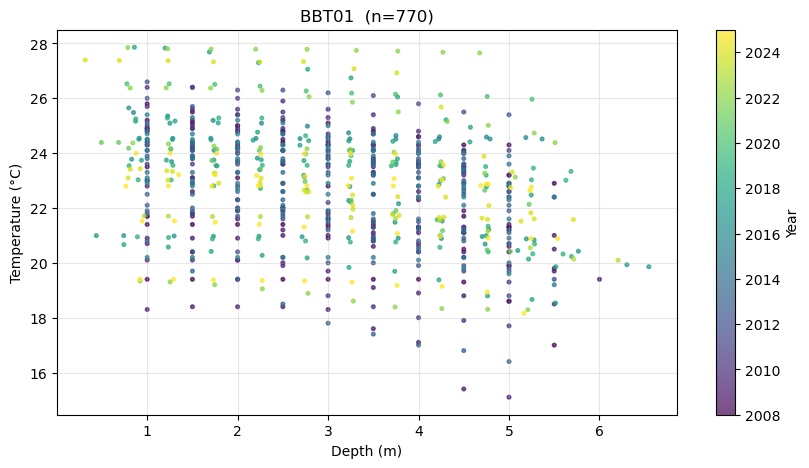

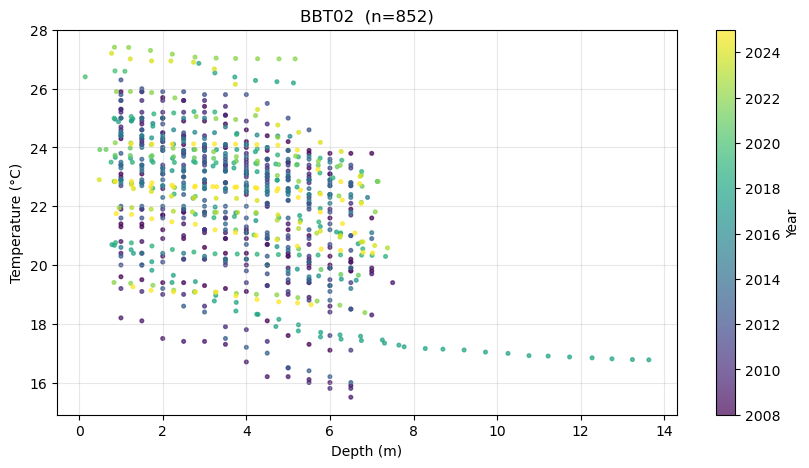

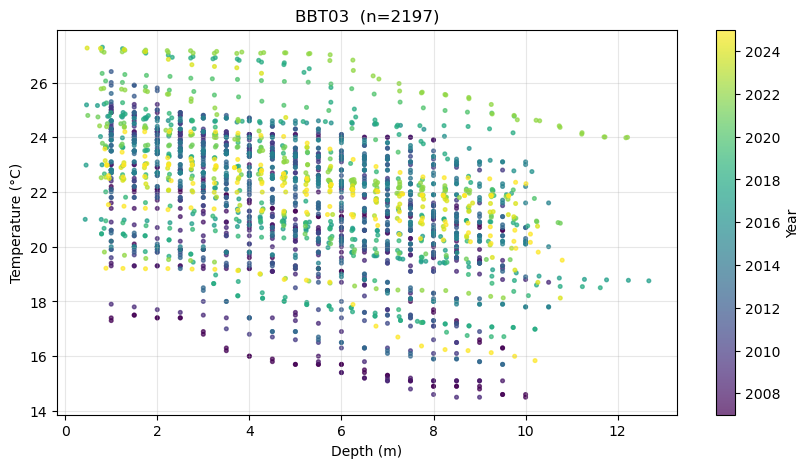

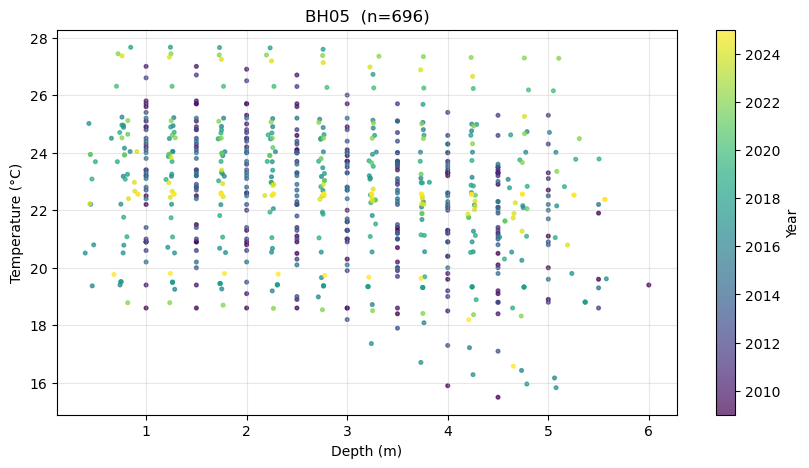

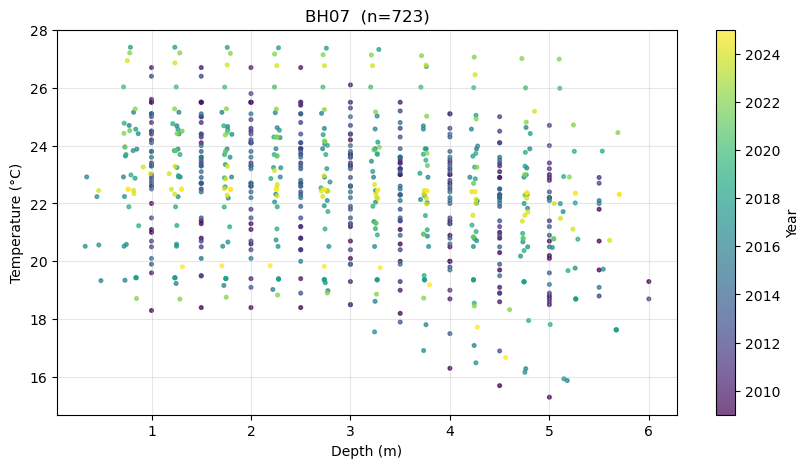

...

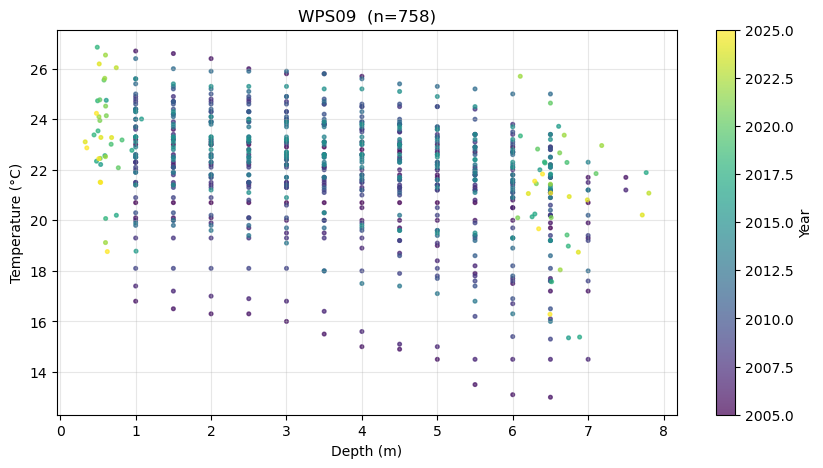

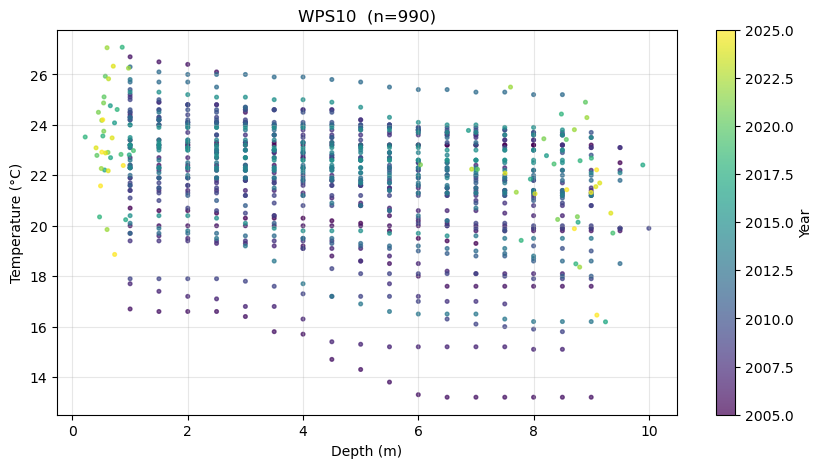

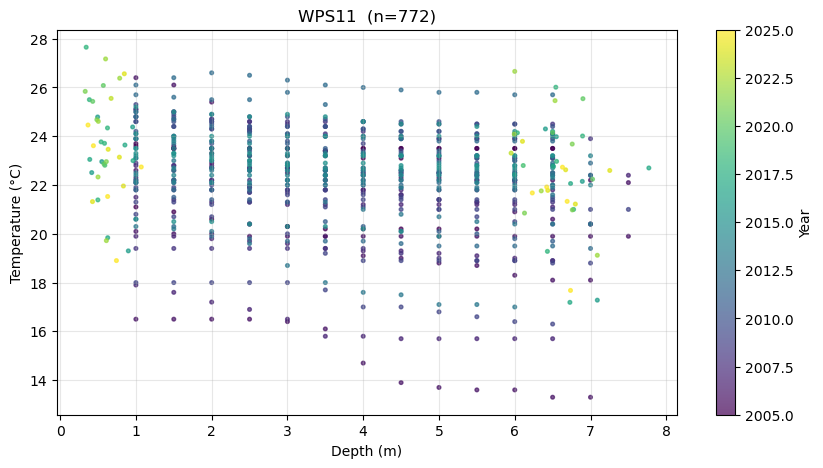

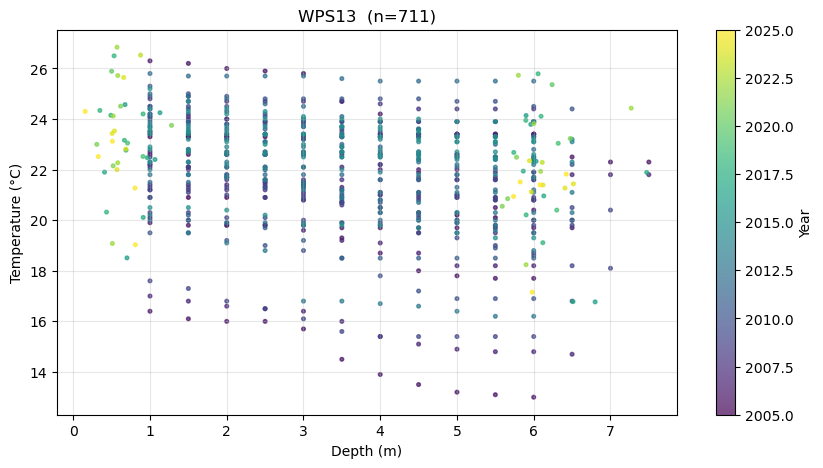

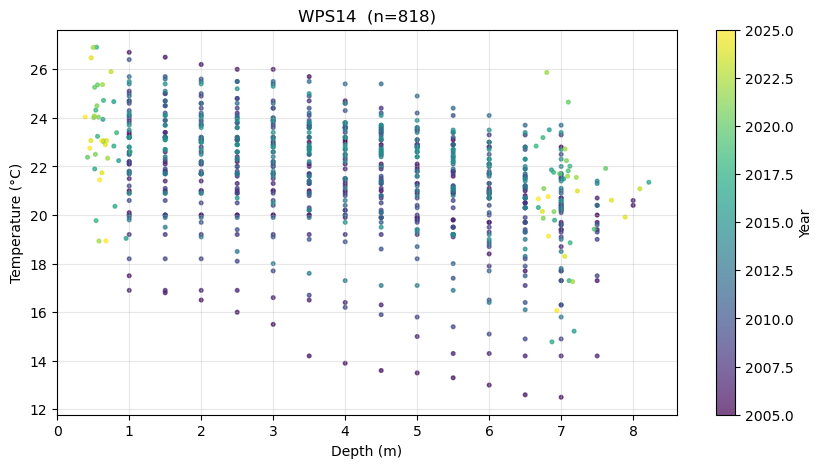

In [46]:
#Temperature Plots
ins_ds["dt"] = (pd.to_datetime(ins_ds["Date"], format="%m/%d/%y", errors="coerce")
                + pd.to_timedelta(ins_ds["Time"].fillna("12:00:00"), errors="coerce"))
for st in stations:
    s = ins_ds[ins_ds["Station"] == st]
    fig, ax = plt.subplots(figsize=(10, 5))
    sc = ax.scatter(s["Depth (m)"], s["Temp (deg C)"], c=s["dt"].dt.year,
                    cmap="viridis", s=7, alpha=0.7)
    ax.set_xlabel("Depth (m)")
    ax.set_ylabel("Temperature (°C)")
    ax.set_title(f"{st}  (n={len(s)})")
    ax.grid(alpha=0.3)
    fig.colorbar(sc, label="Year")
    plt.show()

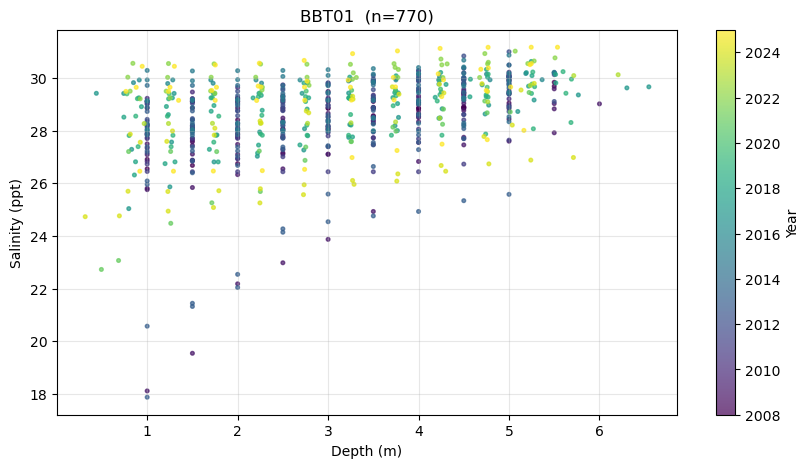

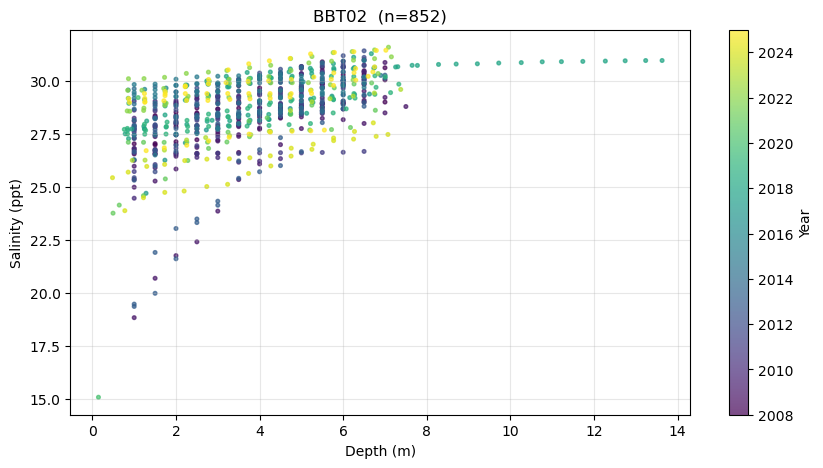

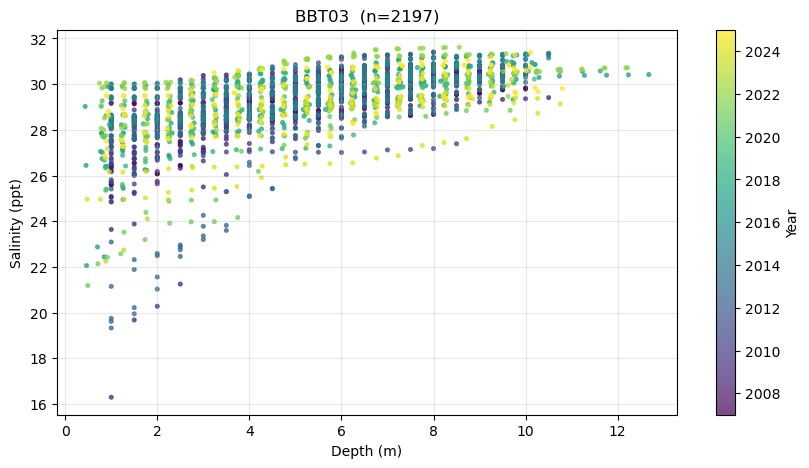

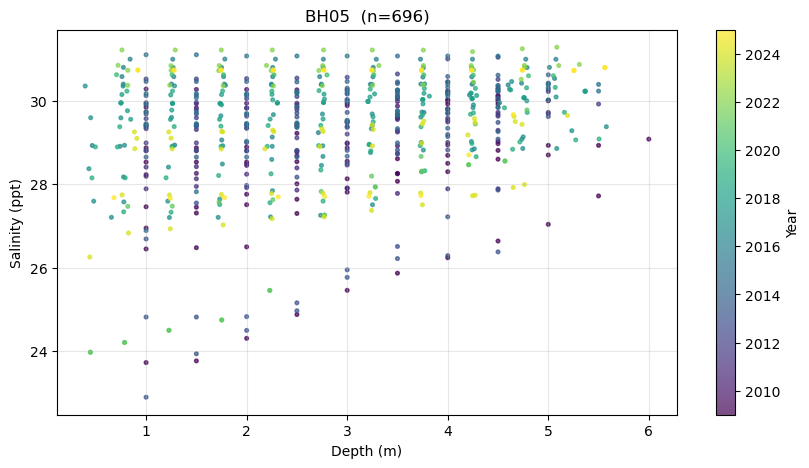

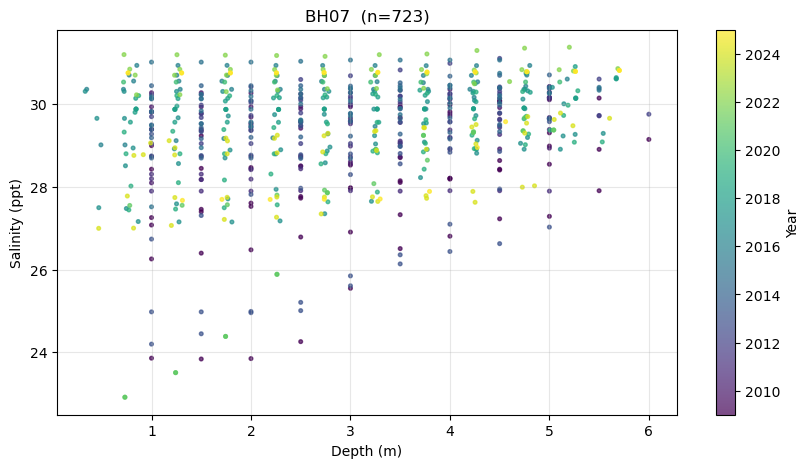

...

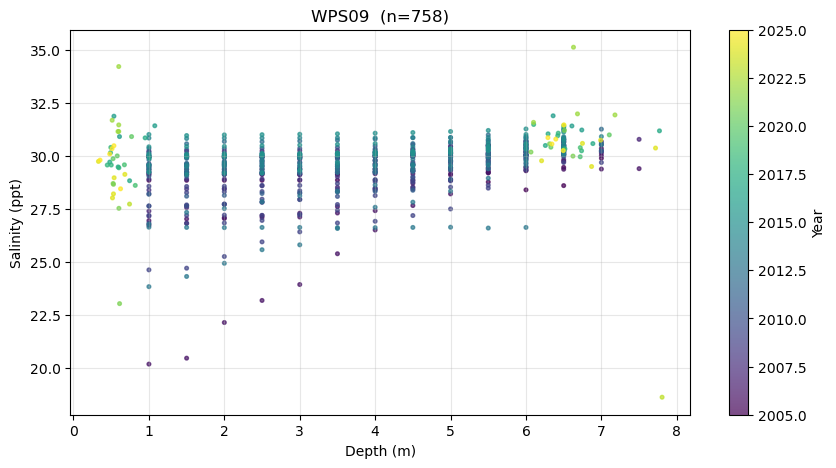

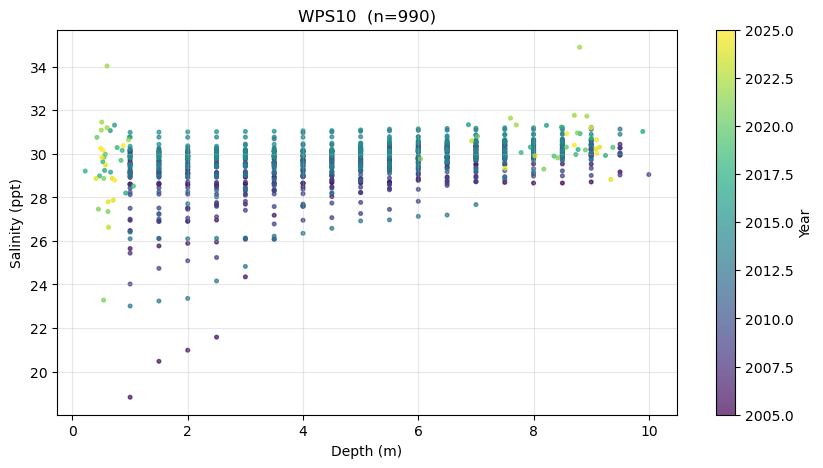

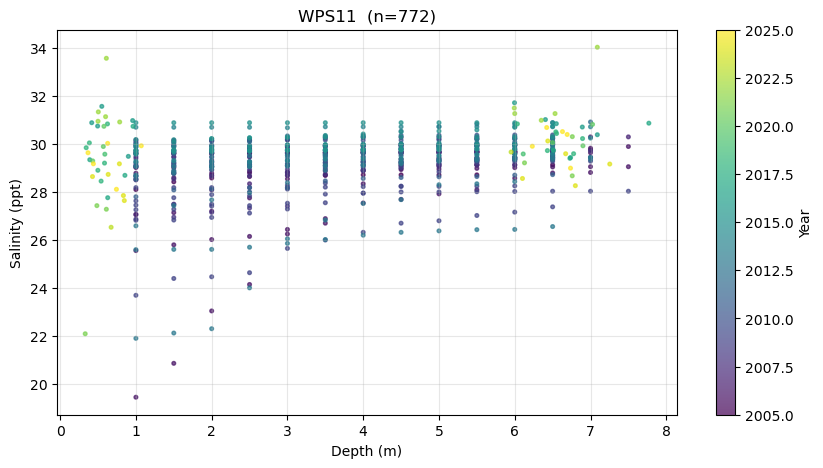

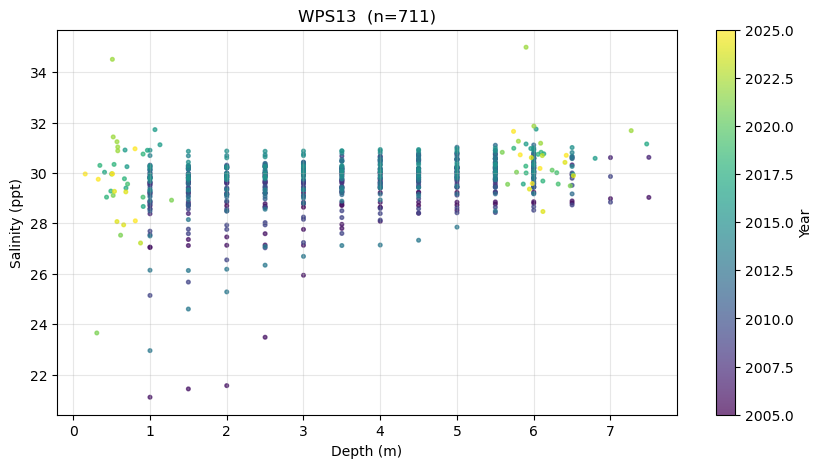

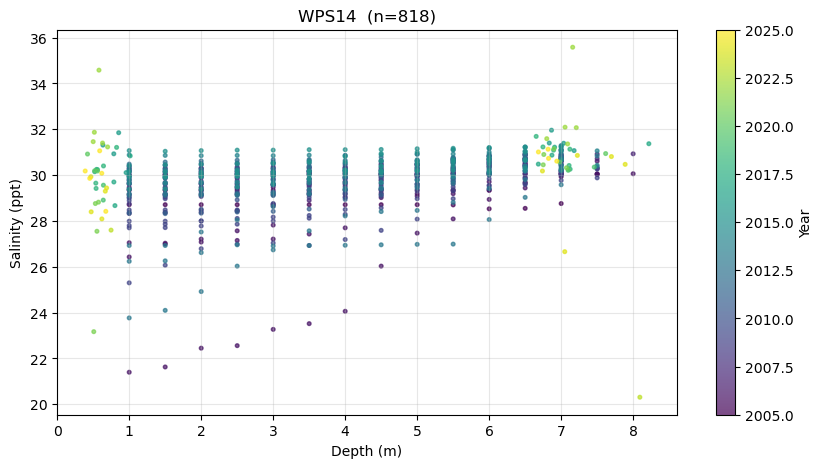

In [48]:
# Salinity Plots
for st in stations:
    s = ins_ds[ins_ds["Station"] == st]
    fig, ax = plt.subplots(figsize=(10, 5))
    sc = ax.scatter(s["Depth (m)"], s["Salinity (ppt)"], c=s["dt"].dt.year,
                    cmap="viridis", s=7, alpha=0.7)
    ax.set_ylabel("Salinity (ppt)")
    ax.set_xlabel("Depth (m)")
    ax.set_title(f"{st}  (n={len(s)})")
    ax.grid(alpha=0.3)
    fig.colorbar(sc, label="Year")
    plt.show()

## Getting model data

In [19]:
# Convert lat, lon -> eta_rho, xi_rho
target_lat, target_lon = 41.6861, -71.4459 #buoy lat-lon

def find_nearest_cell(target_lat, target_lon):
    lat = grd["lat_rho"].values
    lon = grd["lon_rho"].values
    
    dist = (lat - target_lat)**2 + (lon - target_lon)**2
    eta_rho_idx, xi_rho_idx = np.unravel_index(dist.argmin(), dist.shape)

    return eta_rho_idx, xi_rho_idx

eta_rho_idx, xi_rho_idx = find_nearest_cell(target_lat, target_lon)
    
print("eta_rho =", eta_rho_idx)
print("xi_rho  =", xi_rho_idx)
print("cell center:", lat[eta_rho_idx, xi_rho_idx], lon[eta_rho_idx, xi_rho_idx])
print("depth (m):", grd["h"].values[eta_rho_idx, xi_rho_idx])

eta_rho = 807
xi_rho  = 481
cell center: 41.68631044331346 -71.44551968360534
depth (m): 3.108079168818849


In [10]:
# Check available data variables
ds = xr.open_dataset(f"{d}ocean_his_3684.nc")
print(list(ds.variables))

['ntimes', 'ndtfast', 'dt', 'dtfast', 'dstart', 'shuffle', 'deflate', 'deflate_level', 'nHIS', 'ndefHIS', 'nRST', 'nSTA', 'Falpha', 'Fbeta', 'Fgamma', 'nl_tnu2', 'nl_visc2', 'LuvSponge', 'LtracerSponge', 'Akt_bak', 'Akv_bak', 'Akk_bak', 'Akp_bak', 'rdrg', 'rdrg2', 'Zob', 'Zos', 'gls_p', 'gls_m', 'gls_n', 'gls_cmu0', 'gls_c1', 'gls_c2', 'gls_c3m', 'gls_c3p', 'gls_sigk', 'gls_sigp', 'gls_Kmin', 'gls_Pmin', 'Charnok_alpha', 'Zos_hsig_alpha', 'sz_alpha', 'CrgBan_cw', 'Znudg', 'M2nudg', 'M3nudg', 'Tnudg', 'FSobc_in', 'FSobc_out', 'M2obc_in', 'M2obc_out', 'Tobc_in', 'Tobc_out', 'M3obc_in', 'M3obc_out', 'rho0', 'gamma2', 'LuvSrc', 'LwSrc', 'LtracerSrc', 'LsshCLM', 'Lm2CLM', 'Lm3CLM', 'LtracerCLM', 'LnudgeM2CLM', 'LnudgeM3CLM', 'LnudgeTCLM', 'spherical', 'xl', 'el', 'Vtransform', 'Vstretching', 'theta_s', 'theta_b', 'Tcline', 'hc', 's_rho', 's_w', 'Cs_r', 'Cs_w', 'ocean_time', 'zeta', 'ubar_eastward', 'vbar_northward', 'u_eastward', 'v_northward', 'temp', 'salt', 'AKv']


In [16]:
d = "/oscar/data/deeps/shared/OSOM/v2/output/2015/"
starting_year = 2001
day_start = 3684
year_of_interest = starting_year + np.floor(day_start/365)
num_days = 59
file_nums = range(day_start, day_start + num_days)  # 02-01 -> 04-01

times, temps, zetas = [], [], []

for n in file_nums:
    with xr.open_dataset(f"{d}ocean_his_{n}.nc") as f:
        sel = dict(eta_rho=eta_rho_idx, xi_rho=xi_rho_idx)

        cell = f["temp"].isel(**sel)                  # (ocean_time, s_rho)
        times.append(cell["ocean_time"].values)
        temps.append(cell.values)
        zetas.append(f["zeta"].isel(**sel).values)    # (ocean_time,)

        # static terms: identical in every file, so keep the first one
        if n == day_start:
            s_rho = f["s_rho"].values
            Cs_r = f["Cs_r"].values

        print( f"{n} / {(num_days)} files processed", end="\r")

# combine across files
time = np.concatenate(times)
temp = np.concatenate(temps, axis=0)
zeta = np.concatenate(zetas)
print(time.shape, temp.shape, zeta.shape)

(944,) (944, 15) (944,)


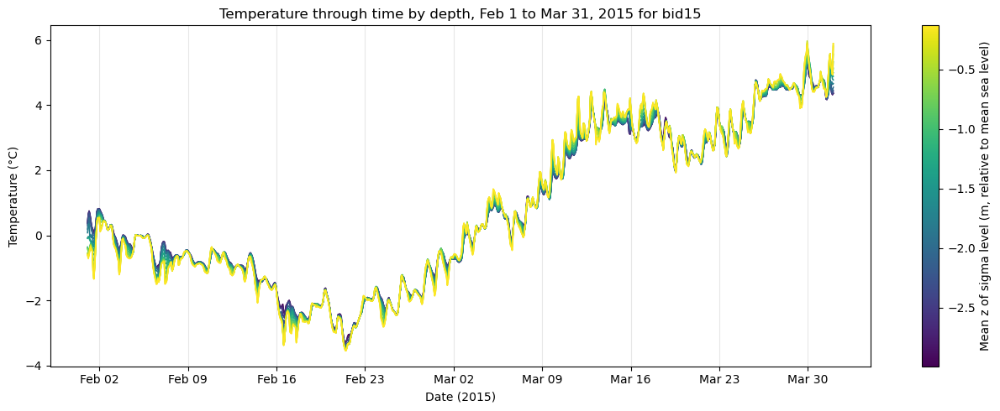

In [17]:
h = float(grd["h"].values[eta_rho_idx, xi_rho_idx])

# zeta: (n_time,) free-surface series at this point
# s_rho, Cs_r: (N,) sigma levels and stretching curve; hc: scalar
zetas = np.asarray(zetas, dtype=float)
s_rho = np.asarray(s_rho, dtype=float)
Cs_r = np.asarray(Cs_r, dtype=float)

# z of every sigma level at every time step -> shape (n_time, N)
z_levels = z(hc, s_rho[None, :], Cs_r[None, :], h, zeta[:, None])

# time-mean z for each level, used for the color gradient
z_mean = z_levels.mean(axis=0)

# map each depth to a color in a gradient
norm = mpl.colors.Normalize(vmin=z_mean.min(), vmax=z_mean.max())
cmap = plt.cm.viridis
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

# plot the temperature over time, for each depth
fig, ax = plt.subplots(figsize=(13, 5))
for k in range(temp.shape[1]):
    ax.plot(time, temp[:, k], color=cmap(norm(z_mean[k])), lw=1.2)

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Mean z of sigma level (m, relative to mean sea level)")

ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.grid(True, axis="x", alpha=0.3)
ax.set_xlabel("Date (2015)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature through time by depth, Feb 1 to Mar 31, 2015 for bid15")
plt.tight_layout()
plt.show()

## Checking depths

In [81]:
# Check depths from model and insomniac
stations = ins_ds["Station"].unique()
station_locs = ins_ds.groupby("Station")[["Lat", "Lon"]].median()
depth_max = ins_ds.groupby("Station")["Depth (m)"].max()

zeta_ref = 0.0     # static check; use the real zeta for both sides if you have it

rows = []
for st in stations:
    lat, lon = station_locs.loc[st, "Lat"], station_locs.loc[st, "Lon"]

    # stations without coordinates can't be matched to a model cell
    if np.isnan(lat) or np.isnan(lon):
        rows.append({"Station": st})
        continue

    eta, xi = find_nearest_cell(lat, lon)
    h = float(grd["h"].values[eta, xi])

    z_model = z(hc, s_rho, Cs_r, h, zeta_ref)[0]            
    z_obs = obs_to_z(depth_max[st], zeta_ref)

    rows.append({
        "Station": st,
        "z_model_deepest": z_model,
        "z_obs_deepest": z_obs,
        "z_diff": z_model - z_obs, #positive = obs deeper than model
        "pct_err": (z_model - z_obs) / abs(z_model) * 100,
    })

z_df = pd.DataFrame(rows).round(2)
z_df

,Station,z_model_deepest,z_obs_deepest,z_diff,pct_err
0,BBT01,-5.17,-6.55,1.38,26.65
1,BBT02,-7.03,-13.63,6.60,93.87
2,BBT03,-9.99,-12.68,2.68,26.85
3,BH05,-4.70,-6.00,1.30,27.66
4,BH07,-3.07,-6.00,2.93,95.23
...,...,...,...,...,...
79,WPS09,-6.52,-7.80,1.29,19.75
80,WPS10,-9.17,-10.00,0.83,9.10
81,WPS11,-6.67,-7.77,1.10,16.51
82,WPS13,-6.36,-7.50,1.14,17.84


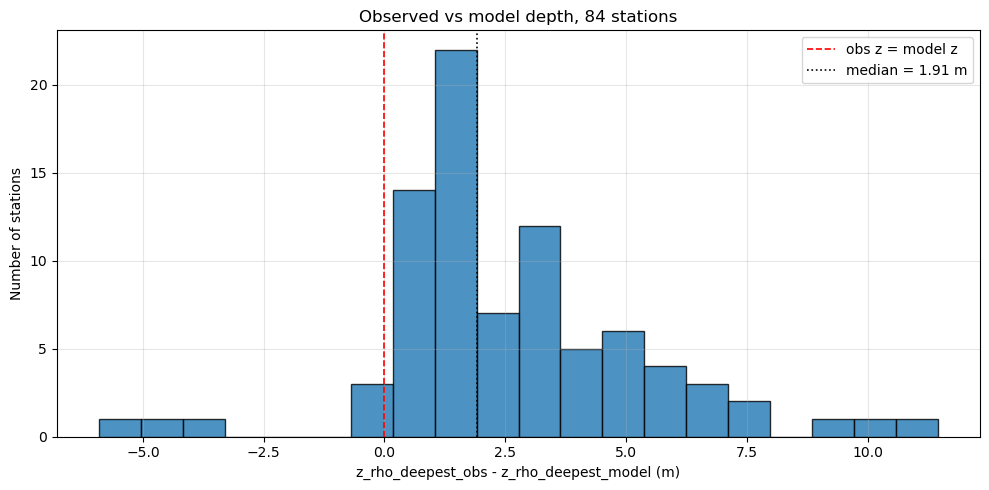

In [83]:
diff = z_df["z_diff"].dropna()   # stations with no model cell are dropped

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(diff, bins=20, color="tab:blue", edgecolor="k", alpha=0.8)
ax.axvline(0, color="r", ls="--", lw=1.2, label="obs z = model z")
ax.set_xlabel("z_model_deepest − z_obs_deepest (m)\n(positive = obs deeper than model)")
ax.axvline(diff.median(), color="k", ls=":", lw=1.2, label=f"median = {diff.median():.2f} m")

ax.set_xlabel("z_rho_deepest_obs - z_rho_deepest_model (m)")
ax.set_ylabel("Number of stations")
ax.set_title(f"Observed vs model depth, {len(diff)} stations")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()